## Author: Gabriel Vance
## Class: DSC550 - Data Mining
## Professor: Dr. Brett Werner
## Date: July 6, 2025

# Purpose: This notebook performs various tasks labeled "Exercises" for Week 4 of the class. Data must be present within the folder that this notebook is run in.
# This week focuses on Classification Models and Clustering

In [64]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from nltk.corpus import stopwords

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    RocCurveDisplay
)

### Get the stemmed data using the same process you did in Week 3.

In [65]:
df = pd.read_csv('training_data.tsv', sep='\t')

### Split this into a training and test set.

In [66]:

train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['sentiment'])

### Fit and apply the tf-idf vectorization to the training set.


In [67]:
tfidf_vectorizer = TfidfVectorizer(stop_words=stopwords.words('english'))
X_train_tfidf = tfidf_vectorizer.fit_transform(train_df['review'])

### Apply but DO NOT FIT the tf-idf vectorization to the test set (Why?).


In [68]:
# Apply the fitted tf-idf vectorizer to the test set
# We do not FIT the tf-idf to avoid data leakage
# Data leakage is when information from outside the training dataset is used to create the model, leading to overly optimistic performance during evaluation.
X_test_tfidf = tfidf_vectorizer.transform(test_df['review'])

### Train a logistic regression using the training data.


In [69]:

logreg = LogisticRegression(max_iter=1000, random_state=42)
logreg.fit(X_train_tfidf, train_df['sentiment'])

LogisticRegression(max_iter=1000, random_state=42)

### Find the model accuracy on the test set.


In [70]:
accuracy = logreg.score(X_test_tfidf, test_df['sentiment'])
print(f"Model accuracy on the test set: {accuracy:.4f}")

Model accuracy on the test set: 0.8960


### Create a confusion matrix for the test set predictions.


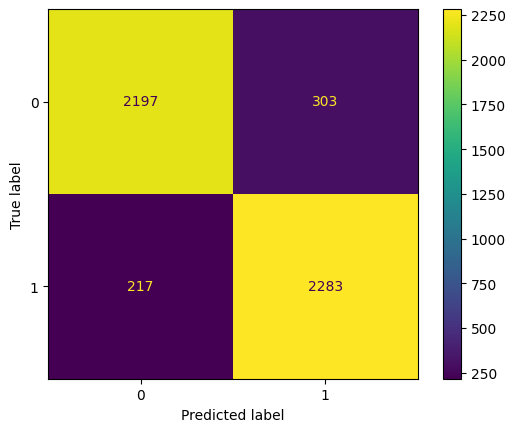

In [71]:

y_pred = logreg.predict(X_test_tfidf)
cm = confusion_matrix(test_df['sentiment'], y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=logreg.classes_)
disp.plot()

### Get the precision, recall, and F1-score for the test set predictions.


In [72]:

precision = precision_score(test_df['sentiment'], y_pred)
recall = recall_score(test_df['sentiment'], y_pred)
f1 = f1_score(test_df['sentiment'], y_pred)

# Precision: Of all predicted positives, how many were actually positive?
# High precision means fewer false positives.
# False Positive (FP): Predicted positive, but actually negative (a "false alarm")
print(f"Precision: {precision:.4f}")  

# Recall (a.k.a. Sensitivity or True Positive Rate): Of all actual positives, how many did we correctly predict?
# High recall means fewer false negatives.
# False Negative (FN): Predicted negative, but actually positive (a "miss")
print(f"Recall:    {recall:.4f}")     

# F1 Score: Harmonic mean of precision and recall.
# It balances both metrics, especially useful when classes are imbalanced.
print(f"F1-score:  {f1:.4f}")        


Precision: 0.8828
Recall:    0.9132
F1-score:  0.8978


### Create a ROC curve for the test set.


c:\Users\Gabe\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_plot\roc_curve.py:189: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  self.ax_.legend(loc="lower right")


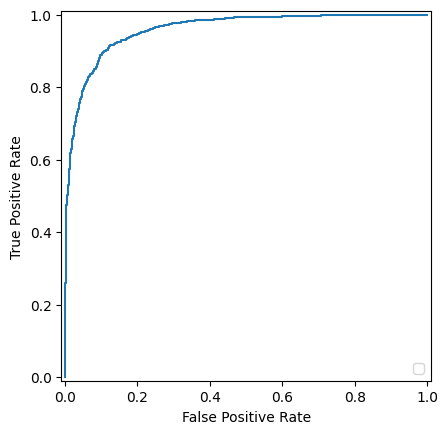

In [73]:

y_proba = logreg.predict_proba(X_test_tfidf)[:, 1]
fpr, tpr, thresholds = roc_curve(test_df['sentiment'], y_proba)
roc_display = RocCurveDisplay(fpr=fpr, tpr=tpr)
roc_display.plot()

### Pick another classification model you learned about this week and repeat steps (5) – (9).


Random Forest accuracy on the test set: 0.8558
Random Forest Precision: 0.8531
Random Forest Recall:    0.8596
Random Forest F1-score:  0.8563


c:\Users\Gabe\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_plot\roc_curve.py:189: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  self.ax_.legend(loc="lower right")


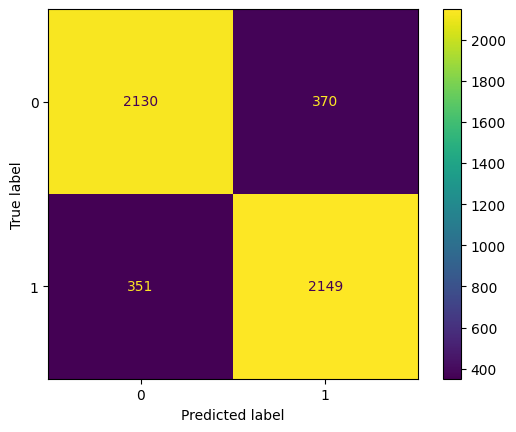

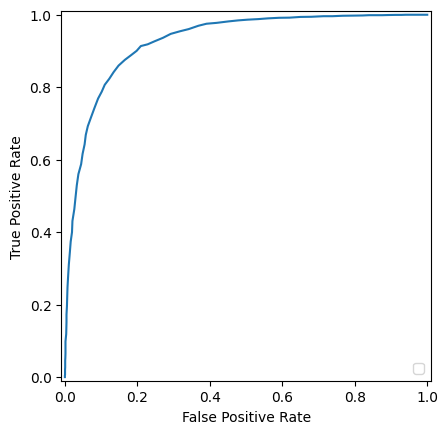

In [74]:

# Train a Random Forest classifier using the training data
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_tfidf, train_df['sentiment'])

# Find the model accuracy on the test set
rf_accuracy = rf.score(X_test_tfidf, test_df['sentiment'])
print(f"Random Forest accuracy on the test set: {rf_accuracy:.4f}")

# Create a confusion matrix for the test set predictions
rf_y_pred = rf.predict(X_test_tfidf)
rf_cm = confusion_matrix(test_df['sentiment'], rf_y_pred)
rf_disp = ConfusionMatrixDisplay(confusion_matrix=rf_cm, display_labels=rf.classes_)
rf_disp.plot()

# Get the precision, recall, and F1-score for the test set predictions
rf_precision = precision_score(test_df['sentiment'], rf_y_pred)
rf_recall = recall_score(test_df['sentiment'], rf_y_pred)
rf_f1 = f1_score(test_df['sentiment'], rf_y_pred)
print(f"Random Forest Precision: {rf_precision:.4f}")
print(f"Random Forest Recall:    {rf_recall:.4f}")
print(f"Random Forest F1-score:  {rf_f1:.4f}")

# Create a ROC curve for the test set
rf_y_proba = rf.predict_proba(X_test_tfidf)[:, 1]
rf_fpr, rf_tpr, rf_thresholds = roc_curve(test_df['sentiment'], rf_y_proba)
rf_roc_display = RocCurveDisplay(fpr=rf_fpr, tpr=rf_tpr)
rf_roc_display.plot()

Logistic Regression (Classification) Metrics:
Accuracy:  0.8960
Precision: 0.8828
Recall:    0.9132
F1-score:  0.8978

Random Forest (Classification) Metrics:
Accuracy:  0.8558
Precision: 0.8531
Recall:    0.8596
F1-score:  0.8563


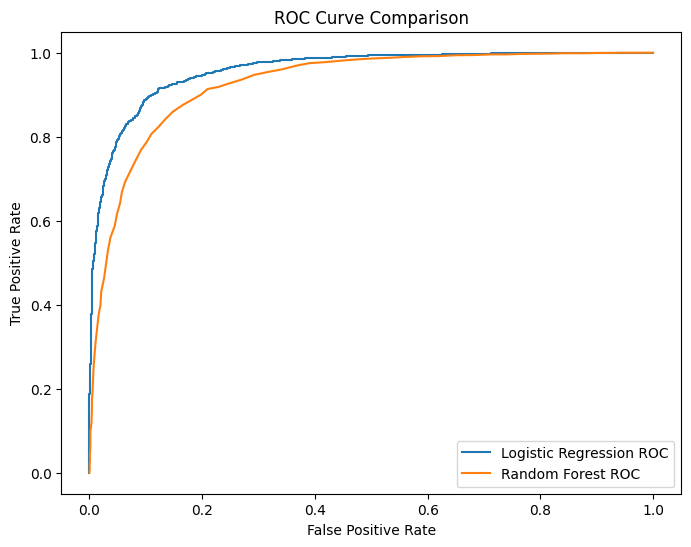

In [75]:
# Compare Regression vs Classification metrics
print("Logistic Regression (Classification) Metrics:")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nRandom Forest (Classification) Metrics:")
print(f"Accuracy:  {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall:    {rf_recall:.4f}")
print(f"F1-score:  {rf_f1:.4f}")

# Plot ROC curves for both models
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label='Logistic Regression ROC')
plt.plot(rf_fpr, rf_tpr, label='Random Forest ROC')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.show()

### Although the classifier was almost as accurate as the regression, the regression model had a higher accuracyAlthough the Random Forest classifier performed comparably to Logistic Regression, the Logistic Regression model achieved a higher overall accuracy and demonstrated superior performance based on the ROC curve.